# Laboratorio 3 Clasificación

## 1. Exploración de los datos

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

import pandas as pd

#%pip install imblearn
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

Dimensiones originales: (12664, 26)
Duplicados: 74
Dimensiones sin duplicados: (12590, 26)


,Faltantes,% faltantes,Valores distintos
vehiculo,12482,99.14,5
frecuencia_cafeteria,217,1.72,5
frecuencia_restaurante_20_a_50,189,1.50,5
frecuencia_comida_para_llevar,150,1.19,5
frecuencia_restaurante_menos_20,129,1.02,5
frecuencia_bar,107,0.85,5
clima,0,0.00,3
temperatura,0,0.00,3
destino,0,0.00,3
acompanante,0,0.00,4



Cafetería: 3979 registros
Faltantes totales: 4213
Duplicados: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
destino,3979,3,Sin lugar urgente,2146,NaN,NaN,NaN,NaN,NaN,NaN,NaN
acompanante,3979,4,Solo,2248,NaN,NaN,NaN,NaN,NaN,NaN,NaN
clima,3979,3,Soleado,3453,NaN,NaN,NaN,NaN,NaN,NaN,NaN
temperatura,3979.0,NaN,NaN,NaN,68.030912,15.988049,30.0,55.0,80.0,80.0,80.0
hora,3979,5,6:00 p.m.,1086,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cupon,3979,1,Cafetería,3979,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vigencia_cupon,3979,2,2 horas,2221,NaN,NaN,NaN,NaN,NaN,NaN,NaN
genero,3979,2,Femenino,2042,NaN,NaN,NaN,NaN,NaN,NaN,NaN
edad,3979,8,21,882,NaN,NaN,NaN,NaN,NaN,NaN,NaN
estado_civil,3979,5,Soltero(a),1545,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Restaurante(<20): 2769 registros
Faltantes totales: 2918
Duplicados: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
destino,2769,3,Sin lugar urgente,1705,NaN,NaN,NaN,NaN,NaN,NaN,NaN
acompanante,2769,4,Solo,1426,NaN,NaN,NaN,NaN,NaN,NaN,NaN
clima,2769,3,Soleado,2228,NaN,NaN,NaN,NaN,NaN,NaN,NaN
temperatura,2769.0,NaN,NaN,NaN,64.182015,19.795489,30.0,55.0,80.0,80.0,80.0
hora,2769,5,6:00 p.m.,744,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cupon,2769,1,Restaurante(<20),2769,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vigencia_cupon,2769,2,2 horas,1423,NaN,NaN,NaN,NaN,NaN,NaN,NaN
genero,2769,2,Femenino,1412,NaN,NaN,NaN,NaN,NaN,NaN,NaN
edad,2769,8,21,569,NaN,NaN,NaN,NaN,NaN,NaN,NaN
estado_civil,2769,5,Casado(a),1107,NaN,NaN,NaN,NaN,NaN,NaN,NaN


acepta_cupon,No,Sí
cupon,,
Cafetería,1996,1983
Restaurante(<20),810,1959


acepta_cupon,No,Sí
cupon,,
Cafetería,50.16,49.84
Restaurante(<20),29.25,70.75


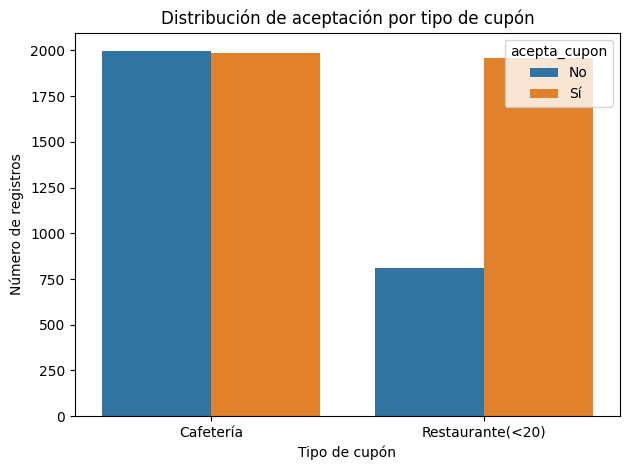


Faltantes en Cafetería (%)


,% faltantes
vehiculo,99.07
frecuencia_cafeteria,1.81
frecuencia_comida_para_llevar,1.43
frecuencia_restaurante_20_a_50,1.38
frecuencia_restaurante_menos_20,1.26
frecuencia_bar,0.93



Faltantes en Restaurante(<20) (%)


,% faltantes
vehiculo,99.10
frecuencia_cafeteria,1.70
frecuencia_restaurante_20_a_50,1.55
frecuencia_comida_para_llevar,1.23
frecuencia_restaurante_menos_20,0.98
frecuencia_bar,0.83


In [16]:
datos = pd.read_excel("./data/Lab3_Datos.xlsx")

# 1. Calidad general y eliminación de duplicados
print("Dimensiones originales:", datos.shape)
print("Duplicados:", datos.duplicated().sum())
datos = datos.drop_duplicates().reset_index(drop=True)
print("Dimensiones sin duplicados:", datos.shape)

calidad = pd.DataFrame({
    "Faltantes": datos.isna().sum(),
    "% faltantes": (datos.isna().mean() * 100).round(2),
    "Valores distintos": datos.nunique()
})
display(calidad.sort_values("% faltantes", ascending=False))

# 2. Características de cada subconjunto
cupones = ["Cafetería", "Restaurante(<20)"]

for cupon in cupones:
    sub = datos[datos["cupon"] == cupon]
    print(f"\n{cupon}: {len(sub)} registros")
    print("Faltantes totales:", sub.isna().sum().sum())
    print("Duplicados:", sub.duplicated().sum())
    display(sub.describe(include="all").T)

# 3. Distribución de acepta_cupon
distribucion = pd.crosstab(
    datos[datos["cupon"].isin(cupones)]["cupon"],
    datos[datos["cupon"].isin(cupones)]["acepta_cupon"]
)
display(distribucion)

porcentajes = pd.crosstab(
    datos[datos["cupon"].isin(cupones)]["cupon"],
    datos[datos["cupon"].isin(cupones)]["acepta_cupon"],
    normalize="index"
) * 100
display(porcentajes.round(2))

# Gráfica de distribución
sns.countplot(
    data=datos[datos["cupon"].isin(cupones)],
    x="cupon", hue="acepta_cupon",
    order=cupones, hue_order=["No", "Sí"]
)
plt.title("Distribución de aceptación por tipo de cupón")
plt.xlabel("Tipo de cupón")
plt.ylabel("Número de registros")
plt.tight_layout()
plt.show()

# 4. Variables con mayor cantidad de faltantes en cada subconjunto
for cupon in cupones:
    sub = datos[datos["cupon"] == cupon]
    faltantes = (sub.isna().mean() * 100).sort_values(ascending=False)
    faltantes = faltantes[faltantes > 0]

    print(f"\nFaltantes en {cupon} (%)")
    display(faltantes.round(2).to_frame("% faltantes"))


### 1. Exploración de los datos

El conjunto de datos original contiene 12.664 registros y 26 variables. Durante la exploración se identificaron 74 filas duplicadas exactas, que fueron eliminadas, obteniendo un conjunto de 12.590 registros. En cuanto a la completitud, la variable `vehiculo` presenta el mayor problema de calidad, con 12.482 valores faltantes (99,14 %). También se encontraron valores faltantes en las variables relacionadas con la frecuencia de consumo, aunque en proporciones considerablemente menores, entre 0,85 % y 1,72 %.

Se analizaron por separado los registros correspondientes a los cupones de Cafetería y Restaurante (`<20`). Para Cafetería se obtuvieron 3.979 registros: 1.996 rechazos (50,16 %) y 1.983 aceptaciones (49,84 %). Esta distribución está prácticamente equilibrada. Por su parte, Restaurante (`<20`) cuenta con 2.769 registros, de los cuales 810 corresponden a rechazos (29,25 %) y 1.959 a aceptaciones (70,75 %). En este segundo subconjunto se observa un desbalance a favor de la aceptación.

La diferencia entre ambas distribuciones es relevante para la construcción y evaluación de los modelos de clasificación. Mientras que en Cafetería las dos clases tienen una representación similar, en Restaurante (`<20`) es necesario prestar especial atención a la capacidad del modelo para identificar los rechazos. Por ello, además de la precisión y el F1-score, se evaluará el recall de la clase minoritaria y se comparará el desempeño del modelo con y sin balanceo de clases.

Finalmente, la exploración de consistencia no encontró incumplimientos en las dos relaciones lógicas de tiempo verificadas. Sin embargo, será necesario ampliar las comprobaciones de validez y revisar el tratamiento de los valores faltantes durante la preparación de los datos. En particular, la elevada proporción de faltantes de `vehiculo` deberá considerarse al seleccionar las variables predictoras y construir los pipelines de preprocesamiento.

## 2. Propuesta de limpieza y preparación de los datos, justificando las decisiones tomadas con base en los resultados obtenidos en el paso anterior.

A partir de la exploración realizada, se propone realizar una limpieza y preparación de los datos que permita mejorar su calidad y adecuarlos a los algoritmos de clasificación. En primer lugar, se eliminarán los 74 registros duplicados exactos identificados en el conjunto original, con el propósito de evitar que observaciones repetidas tengan una influencia excesiva durante el entrenamiento.

En cuanto a los valores faltantes, se propone excluir inicialmente la variable vehiculo de los predictores, debido a que presenta aproximadamente un 99 % de datos ausentes en ambos subconjuntos, lo que limita su utilidad para la predicción. Por otro lado, las variables relacionadas con la frecuencia de consumo presentan porcentajes de faltantes inferiores al 2 %. Por esta razón, se propone imputar estos valores con la categoría más frecuente de cada variable, conservando así la mayor cantidad posible de registros.

Para preparar las variables predictoras, se utilizará codificación One-Hot en las variables categóricas nominales, evitando asignar relaciones de orden artificiales entre sus categorías. Las variables ordinales, como la edad, el nivel educativo, el ingreso y las frecuencias de consumo, se codificarán respetando el orden definido en el diccionario de datos. La temperatura, al ser una variable numérica, se conservará como tal y se estandarizará para los modelos de regresión logística. En los modelos basados en árboles, el escalamiento no será necesario.

Adicionalmente, se construirá un pipeline de preprocesamiento para integrar la imputación, la codificación y el escalamiento que corresponda. Este procedimiento permitirá ajustar las transformaciones únicamente con los datos de entrenamiento durante la validación cruzada, evitando fugas de información hacia los datos de validación y prueba. Los modelos se entrenarán por separado para Cafetería y Restaurante (<20), utilizando una partición estratificada para conservar la distribución de las clases.

Finalmente, debido a que Cafetería presenta una distribución prácticamente equilibrada entre aceptación y rechazo, no se propone aplicar balanceo de clases de manera inicial. En cambio, para Restaurante (<20), donde aproximadamente el 70,75 % de los registros corresponde a aceptaciones, se evaluará el uso de SMOTE. La decisión de aplicar esta técnica se fundamentará en la comparación del F1-score y del recall de la clase minoritaria frente al modelo sin balancear, con el fin de determinar si mejora la identificación de los conductores que rechazan el cupón.

In [18]:

ordinales = {
    "hora": ["7:00 a.m.", "10:00 a.m.", "2:00 p.m.", "6:00 p.m.", "10:00 p.m."],
    "edad": ["menor de 21", "21", "26", "31", "36", "41", "46", "50 o más"],
    "educacion": ["Bachillerato incompleto", "Bachillerato completo",
                  "Estudios universitarios sin título", "Técnico/Tecnólogo",
                  "Pregrado", "Posgrado (Maestría o Doctorado)"],
    "ingreso": ["Menos de $12.500", "$12.500-$24.999", "$25.000-$37.499",
                "$37.500-$49.999", "$50.000-$62.499", "$62.500-$74.999",
                "$75.000-$87.499", "$87.500-$99.999", "$100.000 o más"],
    **{c: ["nunca", "menos de 1", "1 a 3", "4 a 8", "más de 8"]
       for c in ["frecuencia_bar", "frecuencia_cafeteria",
                 "frecuencia_comida_para_llevar",
                 "frecuencia_restaurante_menos_20",
                 "frecuencia_restaurante_20_a_50"]}
}

resultados = {}

for cupon in ["Cafetería", "Restaurante(<20)"]:
    sub = datos.loc[datos["cupon"] == cupon].drop(columns=["cupon", "vehiculo"])
    X = sub.drop(columns="acepta_cupon")
    y = sub["acepta_cupon"].map({"No": 0, "Sí": 1})

    numericas = X.select_dtypes(include="number").columns.tolist()
    ordinales_cols = [c for c in ordinales if c in X.columns]
    nominales = [c for c in X.columns if c not in numericas + ordinales_cols]

    transformadores = []
    if numericas:
        transformadores.append(("num", Pipeline([
            ("imputar", SimpleImputer(strategy="median")),
            ("escalar", StandardScaler())
        ]), numericas))
    if ordinales_cols:
        transformadores.append(("ord", Pipeline([
            ("imputar", SimpleImputer(strategy="most_frequent")),
            ("codificar", OrdinalEncoder(
                categories=[ordinales[c] for c in ordinales_cols],
                handle_unknown="use_encoded_value", unknown_value=-1
            ))
        ]), ordinales_cols))
    if nominales:
        transformadores.append(("nom", Pipeline([
            ("imputar", SimpleImputer(strategy="most_frequent")),
            ("codificar", OneHotEncoder(handle_unknown="ignore"))
        ]), nominales))

    preprocesamiento = ColumnTransformer(transformadores)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    resultados[cupon] = {
        "X_train": X_train,
        "X_test": X_test,
        "y_train": y_train,
        "y_test": y_test,
        "preprocesamiento": preprocesamiento
    }

    print(f"\n{cupon}:")
    print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
    print("Distribución de clases:\n", y_train.value_counts(normalize=True).round(3))


Cafetería:
Entrenamiento: (3183, 23) | Prueba: (796, 23)
Distribución de clases:
 acepta_cupon
0    0.502
1    0.498
Name: proportion, dtype: float64

Restaurante(<20):
Entrenamiento: (2215, 23) | Prueba: (554, 23)
Distribución de clases:
 acepta_cupon
1    0.707
0    0.293
Name: proportion, dtype: float64


## 3. Desarrollar dos modelos de regresión logística, uno para cada tipo de cupón, incorporando una búsqueda de hiperparámetros con validación cruzada, explorando al menos el tipo de regularización y el solver utilizado. Este proceso debe estructurarse mediante un pipeline.

In [21]:

validacion = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

parametros = [
    {
        "modelo__penalty": ["l1", "l2"],
        "modelo__solver": ["liblinear"],
        "modelo__C": [0.01, 0.1, 1, 10]
    },
    {
        "modelo__penalty": ["l1", "l2"],
        "modelo__solver": ["saga"],
        "modelo__C": [0.01, 0.1, 1, 10]
    }
]

modelos_logisticos = {}
metricas_logisticas = []

for cupon, datos_cupon in resultados.items():

    pipeline = Pipeline([
        ("preprocesamiento", datos_cupon["preprocesamiento"]),
        ("modelo", LogisticRegression(
            max_iter=5000,
            random_state=42
        ))
    ])

    busqueda = GridSearchCV(
        estimator=pipeline,
        param_grid=parametros,
        scoring="f1",
        cv=validacion,
        n_jobs=-1,
        refit=True,
        error_score="raise"
    )

    busqueda.fit(
        datos_cupon["X_train"],
        datos_cupon["y_train"]
    )

    mejor_modelo = busqueda.best_estimator_

    predicciones = mejor_modelo.predict(
        datos_cupon["X_test"]
    )

    y_test = datos_cupon["y_test"]

    metricas_logisticas.append({
        "Cupon": cupon,
        "Mejor solver": busqueda.best_params_["modelo__solver"],
        "Regularizacion": busqueda.best_params_["modelo__penalty"],
        "C": busqueda.best_params_["modelo__C"],
        "F1 validacion cruzada": busqueda.best_score_,
        "Accuracy prueba": accuracy_score(y_test, predicciones),
        "Precision prueba": precision_score(
            y_test, predicciones, zero_division=0
        ),
        "Recall prueba": recall_score(
            y_test, predicciones, zero_division=0
        ),
        "F1 prueba": f1_score(
            y_test, predicciones, zero_division=0
        )
    })

    modelos_logisticos[cupon] = {
        "busqueda": busqueda,
        "modelo": mejor_modelo,
        "predicciones": predicciones
    }

    print("\n" + "=" * 60)
    print("CUPÓN:", cupon)
    print("=" * 60)
    print("Mejores hiperparámetros:")
    print(busqueda.best_params_)
    print(f"Mejor F1 en validación cruzada: {busqueda.best_score_:.4f}")
    print("\nReporte de clasificación en prueba:")
    print(classification_report(
        y_test,
        predicciones,
        target_names=["No acepta", "Sí acepta"],
        zero_division=0
    ))

tabla_logistica = pd.DataFrame(metricas_logisticas)

display(tabla_logistica.round(4))


CUPÓN: Cafetería
Mejores hiperparámetros:
{'modelo__C': 0.1, 'modelo__penalty': 'l2', 'modelo__solver': 'liblinear'}
Mejor F1 en validación cruzada: 0.7067

Reporte de clasificación en prueba:
              precision    recall  f1-score   support

   No acepta       0.69      0.68      0.69       399
   Sí acepta       0.68      0.69      0.69       397

    accuracy                           0.69       796
   macro avg       0.69      0.69      0.69       796
weighted avg       0.69      0.69      0.69       796


CUPÓN: Restaurante(<20)
Mejores hiperparámetros:
{'modelo__C': 0.01, 'modelo__penalty': 'l2', 'modelo__solver': 'liblinear'}
Mejor F1 en validación cruzada: 0.8464

Reporte de clasificación en prueba:
              precision    recall  f1-score   support

   No acepta       0.72      0.28      0.41       162
   Sí acepta       0.76      0.95      0.85       392

    accuracy                           0.76       554
   macro avg       0.74      0.62      0.63       554
weigh

,Cupon,Mejor solver,Regularizacion,C,F1 validacion cruzada,Accuracy prueba,Precision prueba,Recall prueba,F1 prueba
0,Cafetería,liblinear,l2,0.10,0.7067,0.6859,0.6833,0.6902,0.6867
1,Restaurante(<20),liblinear,l2,0.01,0.8464,0.7581,0.7633,0.9541,0.8481


En esta etapa se desarrollaron dos modelos de regresión logística, uno para los cupones de Cafetería y otro para los de Restaurante(<20), mediante pipelines que integran el preprocesamiento y la clasificación, junto con una búsqueda de hiperparámetros mediante validación cruzada estratificada de cinco particiones. Se exploraron las regularizaciones L1 y L2, los solvers liblinear y saga, y los valores de C de 0.01, 0.1, 1 y 10, seleccionando las mejores combinaciones según la métrica F1.

Para Cafetería, la combinación óptima fue la regularización L2, el solver liblinear y C = 0.1, con un F1 de validación cruzada de 0.7067 y un F1 de prueba de 0.6867. La exactitud en el conjunto de prueba fue de 0.6859. El recall fue de 0.68 para la clase «No acepta» y de 0.69 para «Sí acepta», lo que refleja un comportamiento relativamente equilibrado entre ambas clases, aunque con una capacidad predictiva moderada.

Para Restaurante(<20), se seleccionaron la regularización L2, el solver liblinear y C = 0.01. El modelo obtuvo un F1 de validación cruzada de 0.8464, un F1 de prueba de 0.8481 y una exactitud de 0.7581. Sin embargo, su desempeño fue desigual entre clases: el recall para «Sí acepta» fue de 0.95, mientras que para «No acepta» fue de solo 0.28. Esto indica que el modelo identifica con facilidad a quienes aceptan el cupón, pero tiene dificultades para reconocer a quienes lo rechazan.

En conclusión, la regresión logística presentó mejores resultados generales para Restaurante(<20) que para Cafetería, especialmente en términos de F1. No obstante, un buen F1 global no garantiza un desempeño equilibrado para todas las clases. Por ello, además de comparar las métricas generales, es importante considerar las métricas por clase y evaluar otros algoritmos de clasificación para determinar cuál ofrece el mejor equilibrio en la predicción de aceptación y rechazo de los cupones.

## 4. Desarrollar dos modelos basados en árboles de decisión, uno para cada tipo de cupón, incorporando una búsqueda de hiperparámetros con validación cruzada que explore la profundidad máxima, el número mínimo de muestras por hoja y el criterio de división. Debe estructurarse mediante un pipeline.

In [23]:

validacion = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

parametros_arbol = {
    "modelo__criterion": ["gini", "entropy"],
    "modelo__max_depth": [None, 5, 10, 20],
    "modelo__min_samples_leaf": [1, 5, 10]
}

modelos_arbol = {}
metricas_arbol = []

for cupon, datos_cupon in resultados.items():

    pipeline = Pipeline([
        ("preprocesamiento", datos_cupon["preprocesamiento"]),
        ("modelo", DecisionTreeClassifier(random_state=42))
    ])

    busqueda = GridSearchCV(
        estimator=pipeline,
        param_grid=parametros_arbol,
        scoring="f1",
        cv=validacion,
        n_jobs=-1,
        refit=True,
        error_score="raise"
    )

    busqueda.fit(
        datos_cupon["X_train"],
        datos_cupon["y_train"]
    )

    mejor_modelo = busqueda.best_estimator_

    predicciones = mejor_modelo.predict(
        datos_cupon["X_test"]
    )

    y_test = datos_cupon["y_test"]

    metricas_arbol.append({
        "Cupon": cupon,
        "Mejor criterio": busqueda.best_params_["modelo__criterion"],
        "Profundidad maxima": busqueda.best_params_["modelo__max_depth"],
        "Minimo muestras por hoja": busqueda.best_params_["modelo__min_samples_leaf"],
        "F1 validacion cruzada": busqueda.best_score_,
        "Accuracy prueba": accuracy_score(y_test, predicciones),
        "Precision prueba": precision_score(
            y_test, predicciones, zero_division=0
        ),
        "Recall prueba": recall_score(
            y_test, predicciones, zero_division=0
        ),
        "F1 prueba": f1_score(
            y_test, predicciones, zero_division=0
        )
    })

    modelos_arbol[cupon] = {
        "busqueda": busqueda,
        "modelo": mejor_modelo,
        "predicciones": predicciones
    }

    print("\n" + "=" * 60)
    print("CUPÓN:", cupon)
    print("=" * 60)
    print("Mejores hiperparámetros:")
    print(busqueda.best_params_)
    print(
        f"Mejor F1 en validación cruzada: "
        f"{busqueda.best_score_:.4f}"
    )

    print("\nReporte de clasificación en prueba:")
    print(classification_report(
        y_test,
        predicciones,
        target_names=["No acepta", "Sí acepta"],
        zero_division=0
    ))

tabla_arbol = pd.DataFrame(metricas_arbol)

display(tabla_arbol.round(4))


CUPÓN: Cafetería
Mejores hiperparámetros:
{'modelo__criterion': 'entropy', 'modelo__max_depth': 5, 'modelo__min_samples_leaf': 1}
Mejor F1 en validación cruzada: 0.7101

Reporte de clasificación en prueba:
              precision    recall  f1-score   support

   No acepta       0.69      0.71      0.70       399
   Sí acepta       0.70      0.69      0.69       397

    accuracy                           0.70       796
   macro avg       0.70      0.70      0.70       796
weighted avg       0.70      0.70      0.70       796


CUPÓN: Restaurante(<20)
Mejores hiperparámetros:
{'modelo__criterion': 'gini', 'modelo__max_depth': 5, 'modelo__min_samples_leaf': 10}
Mejor F1 en validación cruzada: 0.8428

Reporte de clasificación en prueba:
              precision    recall  f1-score   support

   No acepta       0.63      0.37      0.47       162
   Sí acepta       0.78      0.91      0.84       392

    accuracy                           0.75       554
   macro avg       0.70      0.64   

,Cupon,Mejor criterio,Profundidad maxima,Minimo muestras por hoja,F1 validacion cruzada,Accuracy prueba,Precision prueba,Recall prueba,F1 prueba
0,Cafetería,entropy,5,1,0.7101,0.6960,0.6992,0.6851,0.6921
1,Restaurante(<20),gini,5,10,0.8428,0.7527,0.7778,0.9107,0.8390


En esta etapa se desarrollaron dos modelos de clasificación basados en árboles de decisión, uno para los cupones de Cafetería y otro para los de Restaurante(<20). Ambos se estructuraron mediante pipelines que integran el preprocesamiento y el clasificador, y se utilizó GridSearchCV con validación cruzada estratificada de cinco particiones para seleccionar los hiperparámetros según el F1. La búsqueda exploró los criterios de división Gini y entropía, las profundidades máximas None, 5, 10 y 20, y los valores 1, 5 y 10 para el número mínimo de muestras por hoja.

Para Cafetería, la mejor configuración utilizó el criterio entropy, una profundidad máxima de 5 y un mínimo de 1 muestra por hoja. El F1 promedio en validación cruzada fue de 0.7101. En el conjunto de prueba, el modelo alcanzó una exactitud de 0.6960 y un F1 de 0.6921. El recall fue de 0.71 para la clase «No acepta» y de 0.69 para «Sí acepta», lo que indica un desempeño relativamente equilibrado entre ambas clases.

Para Restaurante(<20), la configuración seleccionada utilizó el criterio gini, una profundidad máxima de 5 y un mínimo de 10 muestras por hoja. El F1 promedio en validación cruzada fue de 0.8428. En prueba, obtuvo una exactitud de 0.7527 y un F1 de 0.8390. El recall fue de 0.91 para «Sí acepta», pero de 0.37 para «No acepta», por lo que el modelo identifica mejor a quienes aceptan el cupón que a quienes lo rechazan.

En conclusión, el árbol de decisión de Cafetería mostró una mejora modesta frente a la regresión logística en F1 de prueba (0.6921 frente a 0.6867) y mantuvo un desempeño equilibrado entre clases. Para Restaurante(<20), el árbol obtuvo un F1 de prueba de 0.8390, ligeramente inferior al 0.8481 de la regresión logística, aunque elevó el recall de la clase «No acepta» de 0.28 a 0.37. En ambos tipos de cupón persiste una dificultad para identificar los rechazos en Restaurante(<20), por lo que conviene comparar estos resultados con los de Random Forest y revisar métricas por clase, en lugar de basar la elección únicamente en el F1 global o la exactitud.

## 5. Desarrollar dos modelos basados en Random Forest, uno para cada tipo de cupón, incorporando una búsqueda de hiperparámetros con validación cruzada que explore al menos el número de árboles, la profundidad máxima de estos y el número mínimo de muestras por hoja. Debe estructurarse mediante un pipeline.

In [26]:
validacion = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

parametros_rf = {
    "modelo__n_estimators": [100, 200],
    "modelo__max_depth": [None, 10, 20],
    "modelo__min_samples_leaf": [1, 5, 10]
}

modelos_rf = {}
metricas_rf = []

for cupon, datos_cupon in resultados.items():

    pipeline = Pipeline([
        ("preprocesamiento", datos_cupon["preprocesamiento"]),
        ("modelo", RandomForestClassifier(
            random_state=42,
            n_jobs=1
        ))
    ])

    busqueda = GridSearchCV(
        estimator=pipeline,
        param_grid=parametros_rf,
        scoring="f1",
        cv=validacion,
        n_jobs=-1,
        refit=True,
        error_score="raise"
    )

    busqueda.fit(
        datos_cupon["X_train"],
        datos_cupon["y_train"]
    )

    mejor_modelo = busqueda.best_estimator_

    predicciones = mejor_modelo.predict(
        datos_cupon["X_test"]
    )

    y_test = datos_cupon["y_test"]

    metricas_rf.append({
        "Cupon": cupon,
        "Numero de arboles": busqueda.best_params_[
            "modelo__n_estimators"
        ],
        "Profundidad maxima": busqueda.best_params_[
            "modelo__max_depth"
        ],
        "Minimo muestras por hoja": busqueda.best_params_[
            "modelo__min_samples_leaf"
        ],
        "F1 validacion cruzada": busqueda.best_score_,
        "Accuracy prueba": accuracy_score(
            y_test, predicciones
        ),
        "Precision prueba": precision_score(
            y_test, predicciones, zero_division=0
        ),
        "Recall prueba": recall_score(
            y_test, predicciones, zero_division=0
        ),
        "F1 prueba": f1_score(
            y_test, predicciones, zero_division=0
        )
    })

    modelos_rf[cupon] = {
        "busqueda": busqueda,
        "modelo": mejor_modelo,
        "predicciones": predicciones
    }

    print("\n" + "=" * 60)
    print("CUPÓN:", cupon)
    print("=" * 60)
    print("Mejores hiperparámetros:")
    print(busqueda.best_params_)
    print(
        f"Mejor F1 en validación cruzada: "
        f"{busqueda.best_score_:.4f}"
    )

    print("\nReporte de clasificación en prueba:")
    print(classification_report(
        y_test,
        predicciones,
        target_names=["No acepta", "Sí acepta"],
        zero_division=0
    ))

tabla_rf = pd.DataFrame(metricas_rf)

display(tabla_rf.round(4))


CUPÓN: Cafetería
Mejores hiperparámetros:
{'modelo__max_depth': 20, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 200}
Mejor F1 en validación cruzada: 0.7481

Reporte de clasificación en prueba:
              precision    recall  f1-score   support

   No acepta       0.75      0.73      0.74       399
   Sí acepta       0.74      0.76      0.75       397

    accuracy                           0.75       796
   macro avg       0.75      0.75      0.75       796
weighted avg       0.75      0.75      0.75       796


CUPÓN: Restaurante(<20)
Mejores hiperparámetros:
{'modelo__max_depth': 20, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 200}
Mejor F1 en validación cruzada: 0.8543

Reporte de clasificación en prueba:
              precision    recall  f1-score   support

   No acepta       0.71      0.39      0.50       162
   Sí acepta       0.79      0.93      0.85       392

    accuracy                           0.77       554
   macro avg       0.75      0.66     

,Cupon,Numero de arboles,Profundidad maxima,Minimo muestras por hoja,F1 validacion cruzada,Accuracy prueba,Precision prueba,Recall prueba,F1 prueba
0,Cafetería,200,20,1,0.7481,0.7462,0.7396,0.7582,0.7488
1,Restaurante(<20),200,20,1,0.8543,0.7744,0.7871,0.9337,0.8541


Se desarrollaron dos modelos de clasificación mediante Random Forest, uno para el cupón de Cafetería y otro para Restaurante (<20). Cada modelo se estructuró con un Pipeline que integra el preprocesamiento de los datos y el clasificador RandomForestClassifier.

Para seleccionar los hiperparámetros se utilizó GridSearchCV con validación cruzada estratificada de cinco particiones y la métrica F1 como criterio de selección. La búsqueda exploró el número de árboles (100 y 200), la profundidad máxima (None, 10 y 20) y el número mínimo de muestras por hoja (1, 5 y 10). Se evaluaron 18 combinaciones de hiperparámetros por cada tipo de cupón.

Resultados para Cafetería
Los mejores hiperparámetros fueron 200 árboles, profundidad máxima de 20 y mínimo de 1 muestra por hoja. El F1 promedio en validación cruzada fue 0.7481. En el conjunto de prueba se obtuvo una exactitud de 0.7462, precisión de 0.7396, recall de 0.7582 y F1 de 0.7488. Según el reporte de clasificación, el F1 fue 0.74 para la clase “No acepta” y 0.75 para “Sí acepta”. Esto indica un desempeño relativamente equilibrado entre ambas clases.

Resultados para Restaurante (<20)
Los mejores hiperparámetros también fueron 200 árboles, profundidad máxima de 20 y mínimo de 1 muestra por hoja. El F1 promedio en validación cruzada fue 0.8543. En prueba se obtuvo una exactitud de 0.7744, precisión de 0.7871, recall de 0.9337 y F1 de 0.8541. El reporte por clase muestra un F1 de 0.50 para “No acepta” y de 0.85 para “Sí acepta”. El modelo identifica a la mayoría de las personas que aceptarían el cupón, pero tiene más dificultades para reconocer los casos de rechazo.

Comparación con los modelos anteriores
Para Cafetería, Random Forest obtuvo un F1 de prueba de 0.7488, superior al de regresión logística (0.6867) y al árbol de decisión (0.6921). Para Restaurante (<20), obtuvo un F1 de 0.8541, ligeramente superior al de regresión logística (0.8481) y al árbol de decisión (0.8390).

Conclusión
En estos experimentos, Random Forest fue el modelo con mejor F1 de prueba para ambos tipos de cupón. El resultado de Cafetería es relativamente equilibrado entre las dos clases. En Restaurante (<20), aunque el F1 global es alto, existe un desbalance entre el rendimiento por clase: el recall para “No acepta” es 0.39, frente a 0.93 para “Sí acepta”. Por tanto, el F1 global no refleja por sí solo la dificultad de identificar a quienes rechazarían el cupón. Es pertinente evaluar técnicas de balanceo de clases en el siguiente punto y revisar específicamente el recall y el F1 de la clase minoritaria.

## 6. Para el modelo de Restaurante(<20), evaluar si aplicar una técnica de balanceo de clases (por ejemplo, SMOTE) mejora el desempeño frente al modelo sin balancear. La comparación debe incluir no solo el F1-score general, sino también el recall de la clase minoritaria, y debe concluirse con una recomendación justificada sobre si conviene o no aplicar la técnica.

In [30]:
cupon = "Restaurante(<20)"
datos = resultados[cupon]

X_train = datos["X_train"]
X_test = datos["X_test"]
y_train = datos["y_train"]
y_test = datos["y_test"]

validacion = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Modelo sin balanceo
modelo_sin_balancear = modelos_rf[cupon]["modelo"]
pred_sin_balancear = modelo_sin_balancear.predict(X_test)

# Modelo con SMOTE
pipeline_smote = ImbPipeline([
    ("preprocesamiento", datos["preprocesamiento"]),
    ("smote", SMOTE(random_state=42)),
    ("modelo", RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])

parametros = {
    "modelo__n_estimators": [100, 200],
    "modelo__max_depth": [10, 20],
    "modelo__min_samples_leaf": [1, 5, 10]
}

busqueda_smote = GridSearchCV(
    estimator=pipeline_smote,
    param_grid=parametros,
    scoring="f1",
    cv=validacion,
    n_jobs=-1,
    refit=True
)

busqueda_smote.fit(X_train, y_train)

modelo_smote = busqueda_smote.best_estimator_
pred_smote = modelo_smote.predict(X_test)

def calcular_metricas(nombre, y_real, y_pred):
    return {
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_real, y_pred),
        "Precision (Sí acepta)": precision_score(
            y_real, y_pred, pos_label=1, zero_division=0
        ),
        "Recall (No acepta)": recall_score(
            y_real, y_pred, pos_label=0, zero_division=0
        ),
        "F1 (No acepta)": f1_score(
            y_real, y_pred, pos_label=0, zero_division=0
        ),
        "F1 (Sí acepta)": f1_score(
            y_real, y_pred, pos_label=1, zero_division=0
        ),
        "F1 macro": f1_score(
            y_real, y_pred, average="macro", zero_division=0
        )
    }

comparacion = pd.DataFrame([
    calcular_metricas(
        "Random Forest sin balanceo",
        y_test,
        pred_sin_balancear
    ),
    calcular_metricas(
        "Random Forest con SMOTE",
        y_test,
        pred_smote
    )
])

print("Mejores hiperparámetros con SMOTE:")
print(busqueda_smote.best_params_)

print("\nMejor F1 en validación cruzada:")
print(round(busqueda_smote.best_score_, 4))

print("\nComparación de modelos:")
display(comparacion.round(4))

print("\nReporte sin balanceo:")
print(classification_report(
    y_test,
    pred_sin_balancear,
    labels=[0, 1],
    target_names=["No acepta", "Sí acepta"],
    zero_division=0
))

print("\nReporte con SMOTE:")
print(classification_report(
    y_test,
    pred_smote,
    labels=[0, 1],
    target_names=["No acepta", "Sí acepta"],
    zero_division=0
))

C:\Users\laura\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\numpy\ma\core.py:2881: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,


Mejores hiperparámetros con SMOTE:
{'modelo__max_depth': 20, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 200}

Mejor F1 en validación cruzada:
0.8473

Comparación de modelos:


,Modelo,Accuracy,Precision (Sí acepta),Recall (No acepta),F1 (No acepta),F1 (Sí acepta),F1 macro
0,Random Forest sin balanceo,0.7744,0.7871,0.3889,0.5020,0.8541,0.6781
1,Random Forest con SMOTE,0.7726,0.7995,0.4506,0.5368,0.8493,0.6930



Reporte sin balanceo:
              precision    recall  f1-score   support

   No acepta       0.71      0.39      0.50       162
   Sí acepta       0.79      0.93      0.85       392

    accuracy                           0.77       554
   macro avg       0.75      0.66      0.68       554
weighted avg       0.76      0.77      0.75       554


Reporte con SMOTE:
              precision    recall  f1-score   support

   No acepta       0.66      0.45      0.54       162
   Sí acepta       0.80      0.91      0.85       392

    accuracy                           0.77       554
   macro avg       0.73      0.68      0.69       554
weighted avg       0.76      0.77      0.76       554



Se comparó el modelo Random Forest de Restaurante (<20) sin balanceo con una versión que incorpora SMOTE para aumentar la representación de la clase minoritaria “No acepta”. SMOTE se incluyó dentro del Pipeline y se aplicó durante el entrenamiento, evitando utilizar el conjunto de prueba para generar muestras sintéticas. Los hiperparámetros del modelo con SMOTE se seleccionaron mediante GridSearchCV y validación cruzada estratificada de cinco particiones, usando F1 como criterio de selección.

Los mejores hiperparámetros con SMOTE fueron 200 árboles, profundidad máxima de 20 y mínimo de 1 muestra por hoja. El mejor F1 en validación cruzada fue 0.8473.

En el conjunto de prueba, el modelo sin balanceo obtuvo una exactitud de 0.7744, recall de 0.3889 y F1 de 0.5020 para la clase “No acepta”, F1 de 0.8541 para “Sí acepta” y F1 macro de 0.6781. Con SMOTE, la exactitud fue 0.7726, el recall de “No acepta” aumentó a 0.4506 y su F1 aumentó a 0.5368. El F1 de “Sí acepta” fue 0.8493 y el F1 macro subió a 0.6930.

La comparación muestra que SMOTE aumentó el recall de la clase minoritaria en 6.17 puntos porcentuales y su F1 en 3.48 puntos porcentuales. El F1 macro también mejoró en 1.49 puntos porcentuales. Por otro lado, la exactitud disminuyó 0.18 puntos porcentuales y el F1 de “Sí acepta” disminuyó 0.48 puntos porcentuales, cambios pequeños en comparación con la mejora observada para la clase minoritaria.


## 7. Elaboración de una tabla comparativa mostrando el rendimiento sobre test de los modelos construidos (regresión logística, árbol de decisión, Random Forest), para cada tipo de cupón, con base en las métricas recall, precisión y F1-score.

In [37]:
modelos_evaluados = {
    "Regresión logística": modelos_logisticos,
    "Árbol de decisión": modelos_arbol,
    "Random Forest": modelos_rf
}

filas = []

for nombre_modelo, modelos in modelos_evaluados.items():
    for cupon, datos in resultados.items():

        modelo = modelos[cupon]["modelo"]
        y_test = datos["y_test"]
        predicciones = modelo.predict(datos["X_test"])

        filas.append({
            "Tipo de cupón": cupon,
            "Modelo": nombre_modelo,
            "Precisión": precision_score(
                y_test, predicciones, zero_division=0
            ),
            "Recall": recall_score(
                y_test, predicciones, zero_division=0
            ),
            "F1-score": f1_score(
                y_test, predicciones, zero_division=0
            )
        })

tabla_comparativa = pd.DataFrame(filas)

display(
    tabla_comparativa.style.format({
        "Precisión": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}"
    })
)

,Tipo de cupón,Modelo,Precisión,Recall,F1-score
0,Cafetería,Regresión logística,0.6833,0.6902,0.6867
1,Restaurante(<20),Regresión logística,0.7633,0.9541,0.8481
2,Cafetería,Árbol de decisión,0.6992,0.6851,0.6921
3,Restaurante(<20),Árbol de decisión,0.7778,0.9107,0.8390
4,Cafetería,Random Forest,0.7396,0.7582,0.7488
5,Restaurante(<20),Random Forest,0.7871,0.9337,0.8541


En conclusión, Random Forest es el modelo recomendado entre los tres evaluados para ambos tipos de cupón, dado que obtuvo el F1-score más alto en el conjunto de prueba. No obstante, estas métricas corresponden a la clase “Sí acepta”. En el caso de Restaurante (<20), los resultados del punto 6 muestran que el modelo sin balanceo tiene dificultades para identificar la clase “No acepta”; por tanto, si también es importante detectar a quienes rechazarían el cupón, conviene considerar la evaluación con SMOTE y valorar el recall y el F1 de esa clase.

## 8. Identificación de las variables más relevantes en la predicción para los dos tipos de cupón, con el fin de comprender qué factores del contexto o del perfil del conductor influyen más en cada caso.


CUPÓN: Cafetería


,Variable,Importancia
0,ocupacion,0.1566
1,frecuencia_cafeteria,0.1472
2,edad,0.0647
3,estado_civil,0.0555
4,educacion,0.0517
5,frecuencia_comida_para_llevar,0.0488
6,frecuencia_bar,0.0485
7,frecuencia_restaurante_20_a_50,0.0470
8,frecuencia_restaurante_menos_20,0.0454
9,vigencia_cupon,0.0423


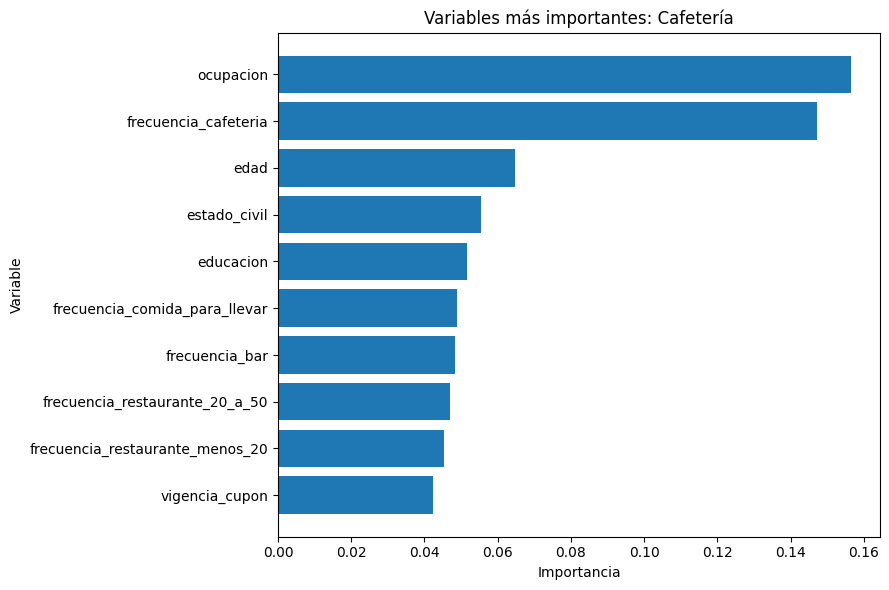


CUPÓN: Restaurante(<20)


,Variable,Importancia
0,ocupacion,0.1584
1,edad,0.0647
2,frecuencia_cafeteria,0.0614
3,estado_civil,0.0569
4,educacion,0.0559
5,hora,0.0542
6,frecuencia_comida_para_llevar,0.0536
7,frecuencia_restaurante_menos_20,0.0498
8,frecuencia_bar,0.0496
9,vigencia_cupon,0.0489


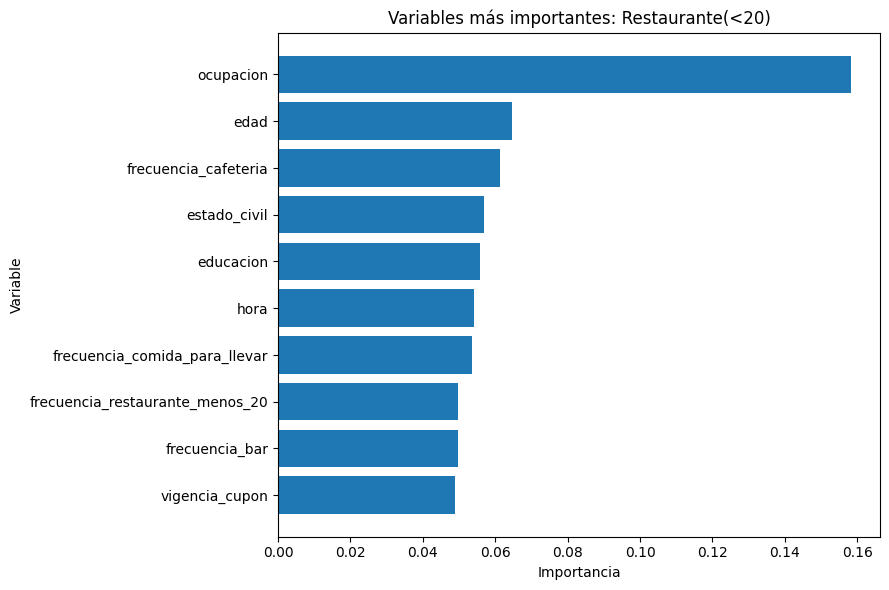

,Modelo,Accuracy,Precision (Sí acepta),Recall (No acepta),F1 (No acepta),F1 (Sí acepta),F1 macro
0,Random Forest sin balanceo,0.774368,0.787097,0.388889,0.501992,0.854142,0.678067
1,Random Forest con SMOTE,0.772563,0.799550,0.450617,0.536765,0.849282,0.693024


In [39]:
import pandas as pd
import matplotlib.pyplot as plt

importancias_variables = {}

for cupon, datos_modelo in modelos_rf.items():

    modelo = datos_modelo["modelo"]
    preprocesamiento = modelo.named_steps["preprocesamiento"]
    clasificador = modelo.named_steps["modelo"]

    nombres_transformados = preprocesamiento.get_feature_names_out()
    importancias = clasificador.feature_importances_

    # Asociar cada columna transformada con su variable original
    mapa_variables = {}

    for nombre, transformador, columnas in preprocesamiento.transformers_:

        if nombre == "remainder" or columnas is None:
            continue

        if isinstance(columnas, str):
            columnas = [columnas]
        elif not isinstance(columnas, (list, tuple)):
            columnas = list(columnas)

        for columna in columnas:
            mapa_variables[columna] = columna

    columnas_originales = sorted(
        mapa_variables.keys(),
        key=len,
        reverse=True
    )

    importancia_original = {}

    for nombre, importancia in zip(nombres_transformados, importancias):

        nombre_limpio = nombre.split("__", 1)[-1]
        variable_original = nombre_limpio

        for columna in columnas_originales:
            if (
                nombre_limpio == columna
                or nombre_limpio.startswith(columna + "_")
            ):
                variable_original = columna
                break

        importancia_original[variable_original] = (
            importancia_original.get(variable_original, 0)
            + importancia
        )

    tabla = pd.DataFrame(
        list(importancia_original.items()),
        columns=["Variable", "Importancia"]
    ).sort_values(
        "Importancia",
        ascending=False
    ).reset_index(drop=True)

    importancias_variables[cupon] = tabla

    print("\n" + "=" * 50)
    print("CUPÓN:", cupon)
    print("=" * 50)

    display(tabla.head(10).round(4))

    principales = tabla.head(10).sort_values("Importancia")

    plt.figure(figsize=(9, 6))
    plt.barh(
        principales["Variable"],
        principales["Importancia"]
    )
    plt.xlabel("Importancia")
    plt.ylabel("Variable")
    plt.title(f"Variables más importantes: {cupon}")
    plt.tight_layout()
    plt.show()


# Comparar las importancias entre los dos cupones
comparacion_importancias = pd.merge(
    importancias_variables["Cafetería"].rename(
        columns={"Importancia": "Importancia Cafetería"}
    ),
    importancias_variables["Restaurante(<20)"].rename(
        columns={"Importancia": "Importancia Restaurante(<20)"}
    ),
    on="Variable",
    how="outer"
).fillna(0)

comparacion_importancias["Diferencia absoluta"] = (
    comparacion_importancias["Importancia Cafetería"]
    - comparacion_importancias["Importancia Restaurante(<20)"]
).abs()

comparacion

Se analizaron las importancias de las variables de los modelos Random Forest entrenados para los cupones de Cafetería y Restaurante (<20). Para interpretar las variables categóricas, las importancias de las columnas generadas por el preprocesamiento se agruparon por variable original.

En ambos modelos, la ocupación fue la variable más importante. Su importancia fue 0.1566 para Cafetería y 0.1584 para Restaurante (<20), lo que indica que esta característica tuvo la mayor contribución relativa a las predicciones de los dos modelos.

Para Cafetería, las siguientes variables más relevantes fueron la frecuencia de visita a cafeterías (0.1472), la edad (0.0647), el estado civil (0.0555) y la educación (0.0517). También aparecieron entre las diez variables principales la frecuencia de compra de comida para llevar (0.0488), la frecuencia de visita a bares (0.0485), la frecuencia de visita a restaurantes de precio medio (0.0470), la frecuencia de visita a restaurantes de menos de 20 dólares (0.0454) y la vigencia del cupón (0.0423). La importancia de la frecuencia de visita a cafeterías sugiere que los hábitos de consumo relacionados con este establecimiento son especialmente informativos para el modelo.

Para Restaurante (<20), después de la ocupación destacaron la edad (0.0647), la frecuencia de visita a cafeterías (0.0614), el estado civil (0.0569), la educación (0.0559) y la hora (0.0542). También fueron relevantes la frecuencia de compra de comida para llevar (0.0536), la frecuencia de visita a restaurantes de menos de 20 dólares (0.0498), la frecuencia de visita a bares (0.0496) y la vigencia del cupón (0.0489). En este modelo, la hora aparece entre las diez variables principales, lo que sugiere que el contexto temporal aporta información para la predicción.

En comparación, los dos modelos comparten varias variables importantes: ocupación, edad, frecuencia de visita a cafeterías, estado civil, educación, frecuencia de compra de comida para llevar, frecuencia de visita a bares, frecuencia de visita a restaurantes de menos de 20 dólares y vigencia del cupón. La diferencia más visible entre las listas de diez variables principales es que para Cafetería aparece la frecuencia de visita a restaurantes de precio entre 20 y 50 dólares, mientras que para Restaurante (<20) aparece la hora.

En conclusión, los modelos consideran relevantes tanto características sociodemográficas del conductor como sus hábitos de consumo. La ocupación sobresale en ambos tipos de cupón, mientras que la frecuencia de visita a cafeterías tiene especial importancia para predecir la aceptación del cupón de Cafetería. Para Restaurante (<20), también destaca la hora. Estas importancias son medidas relativas de contribución al modelo: no indican por sí solas si una variable aumenta o disminuye la probabilidad de aceptar un cupón ni demuestran una relación causal.

## 10. Generación de predicciones sobre los datos compartidos que no se encuentran etiquetados (Lab3_datos_Prueba), utilizando el mejor modelo obtenido para cada tipo de cupón. Exportar las predicciones en formato CSV utilizando como base el mismo archivo de datos dado.

In [41]:

# 1. Cargar los datos de prueba sin etiquetas
datos_prueba = pd.read_excel("./data/Lab3_datos_Prueba.xlsx")

# Conservar una copia de los datos originales
predicciones_finales = datos_prueba.copy()

# 2. Predecir la aceptación para cada tipo de cupón
for cupon in ["Cafetería", "Restaurante(<20)"]:

    # Recuperar el mejor modelo Random Forest entrenado
    modelo = modelos_rf[cupon]["modelo"]

    # Usar las mismas variables utilizadas durante el entrenamiento
    columnas_modelo = resultados[cupon]["X_train"].columns

    # Seleccionar las variables de entrada
    X_prueba = datos_prueba[columnas_modelo].copy()

    # Generar predicciones
    predicciones = modelo.predict(X_prueba)

    # Convertir las etiquetas numéricas a categorías originales
    predicciones = pd.Series(predicciones).map({
        0: "No",
        1: "Sí"
    })

    # Agregar una columna por tipo de cupón
    if cupon == "Cafetería":
        predicciones_finales["prediccion_cafeteria"] = (
            predicciones.values
        )
    else:
        predicciones_finales["prediccion_restaurante_menos_20"] = (
            predicciones.values
        )

# 3. Exportar los resultados a CSV
predicciones_finales.to_csv(
    "Lab3_Predicciones_Punto_10.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Predicciones generadas correctamente.")
print("Archivo: Lab3_Predicciones_Punto_10.csv")
print("\nPrimeras filas:")
display(predicciones_finales.head())

print("\nCantidad de predicciones:")
print(
    predicciones_finales[
        [
            "prediccion_cafeteria",
            "prediccion_restaurante_menos_20"
        ]
    ].apply(pd.Series.value_counts)
)

Predicciones generadas correctamente.
Archivo: Lab3_Predicciones_Punto_10.csv

Primeras filas:


,destino,acompanante,clima,temperatura,hora,cupon,vigencia_cupon,genero,edad,estado_civil,...,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_5min,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,direccion_opuesta,prediccion_cafeteria,prediccion_restaurante_menos_20
0,Trabajo,Solo,Soleado,55,7:00 a.m.,Cafetería,2 horas,Femenino,50 o más,Divorciado(a),...,4 a 8,4 a 8,menos de 1,Sí,Sí,No,No,Sí,No,No
1,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Cafetería,2 horas,Femenino,31,Unión libre,...,más de 8,4 a 8,1 a 3,Sí,No,No,No,Sí,Sí,Sí
2,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,2 horas,Femenino,31,Soltero(a),...,4 a 8,más de 8,menos de 1,Sí,Sí,No,No,Sí,Sí,Sí
3,Sin lugar urgente,Pareja,Soleado,80,10:00 a.m.,Cafetería,2 horas,Masculino,50 o más,Casado(a),...,nunca,4 a 8,menos de 1,Sí,No,No,No,Sí,Sí,Sí
4,Sin lugar urgente,Amigo(s),Soleado,80,6:00 p.m.,Restaurante(<20),2 horas,Femenino,26,Soltero(a),...,4 a 8,menos de 1,4 a 8,Sí,Sí,No,No,Sí,Sí,Sí



Cantidad de predicciones:
    prediccion_cafeteria  prediccion_restaurante_menos_20
Sí                    11                               18
No                     9                                2


Se utilizaron los modelos Random Forest seleccionados para los cupones de Cafetería y Restaurante (<20) para generar predicciones sobre los registros sin etiquetar de Lab3_datos_Prueba. Las predicciones se agregaron al archivo original en dos columnas: “prediccion_cafeteria” y “prediccion_restaurante_menos_20”. Finalmente, los datos se exportaron a formato CSV para conservar las variables originales junto con las predicciones.

El archivo de prueba contiene 20 registros. Para el cupón de Cafetería, el modelo predijo que 11 registros aceptarían el cupón (55 %) y que 9 lo rechazarían (45 %). Para el cupón de Restaurante (<20), predijo que 18 registros aceptarían el cupón (90 %) y que 2 lo rechazarían (10 %).

En conclusión, el procedimiento permitió generar las predicciones solicitadas y exportarlas junto con los datos originales. Según los modelos, la aceptación prevista es mayor para el cupón de Restaurante (<20) que para el de Cafetería. Sin embargo, dado que los registros no tienen etiquetas reales conocidas, estos porcentajes representan únicamente las predicciones de los modelos y no pueden interpretarse como tasas reales de aceptación ni como una medida de exactitud del modelo en esos registros.

## Análisis de resultados.


1. ¿Qué características del contexto de conducción o del perfil del conductor parecen estar más relacionadas con la aceptación de cada tipo de cupón?

De acuerdo con los modelos Random Forest, la ocupación es la variable más importante para los dos tipos de cupón. Su importancia es de 0.1566 para Cafetería y 0.1584 para Restaurante (<20). Esto quiere decir que la ocupación ayuda bastante al modelo a distinguir entre las personas que aceptarían o no el cupón, aunque no significa que una ocupación específica garantice la aceptación.

En el caso de Cafetería, también destaca la frecuencia con la que la persona visita cafeterías (0.1472). Después aparecen la edad (0.0647), el estado civil (0.0555) y la educación (0.0517). Tiene sentido que los hábitos de consumo sean importantes para este cupón, ya que la frecuencia de visita a cafeterías aporta información sobre las preferencias de los conductores.

Para Restaurante (<20), las variables que siguen en importancia son la edad (0.0647), la frecuencia de visita a cafeterías (0.0614), el estado civil (0.0569), la educación (0.0559) y la hora (0.0542). En este caso, además del perfil del conductor, el momento en que se ofrece el cupón parece aportar información al modelo.

Es importante aclarar que la importancia de una variable no nos dice si aumenta o disminuye la probabilidad de aceptar el cupón. Solo muestra qué variables fueron más útiles para las predicciones del modelo.

2. ¿Existen variables que podrían ser redundantes o poco informativas?

Sí. Algunas variables describen hábitos de consumo parecidos, como la frecuencia de visita a cafeterías, bares, restaurantes de diferentes rangos de precio y la compra de comida para llevar. Es posible que varias de ellas estén relacionadas y aporten información similar al modelo.

Además, las variables que no aparecen entre las diez más importantes podrían tener una contribución menor. Sin embargo, esto no significa que sean inútiles: para saberlo con mayor seguridad habría que revisar todas las importancias y evaluar cómo cambia el desempeño al retirar algunas variables. También sería conveniente comprobar si hay variables muy correlacionadas o con muchos datos faltantes.

3. ¿El desempeño y el comportamiento de los modelos difieren entre Cafetería y Restaurante(<20)? Si es así, ¿A qué atribuye esa diferencia?

Sí. Para Cafetería, Random Forest obtuvo un F1-score de 0.7488, por encima de la regresión logística (0.6867) y el árbol de decisión (0.6921). Para Restaurante (<20), también fue el mejor según esta métrica, con un F1-score de 0.8541, seguido de la regresión logística (0.8481) y el árbol de decisión (0.8390).

Una diferencia importante está en la distribución de las clases. En el conjunto de prueba de Cafetería había 399 casos de “No acepta” y 397 de “Sí acepta”, por lo que las clases estaban equilibradas. En Restaurante (<20), en cambio, había 162 casos de “No acepta” y 392 de “Sí acepta”. Al haber más ejemplos de aceptación, el modelo puede aprender mejor a reconocer esa clase y obtener métricas altas para ella, pero tener más dificultades para detectar los rechazos.

Por eso, aunque Restaurante (<20) muestra un F1-score más alto para “Sí acepta”, es importante revisar también las métricas de “No acepta” y no quedarse únicamente con el resultado global.

4. ¿Aplicar balanceo de clases en Restaurante(<20) mejoró el modelo? Justifique considerando tanto el F1-score general, así como el recall de la clase minoritaria.

Sí, SMOTE produjo una mejora moderada en la identificación de la clase minoritaria “No acepta”. Sin balanceo, el recall de esta clase fue de 0.3889 y su F1-score de 0.5020. Con SMOTE, el recall subió a 0.4506 y el F1-score a 0.5368. También mejoró el F1 macro, que pasó de 0.6781 a 0.6930.

Por otro lado, el accuracy bajó ligeramente, de 0.7744 a 0.7726, y el F1-score de “Sí acepta” pasó de 0.8541 a 0.8493. Estos cambios son pequeños en comparación con la mejora en la clase minoritaria.

Por lo tanto, sí recomendaría SMOTE si es importante identificar a las personas que probablemente no acepten el cupón. Aun así, la mejora no resuelve por completo el problema: el recall de “No acepta” sigue siendo de 0.4506, lo que significa que el modelo todavía deja sin identificar más de la mitad de los rechazos reales.

5. A partir de alguno de los modelos de árbol o Random Forest describa, en términos de reglas o de importancia de variables, las características que llevan a aceptar o rechazar un cupón. Incluya la utilidad y la limitación de este tipo de interpretación.

A partir de la importancia de variables de Random Forest, se observa que la ocupación es la característica más relevante en ambos tipos de cupón. Para Cafetería también destaca la frecuencia de visita a cafeterías, mientras que para Restaurante (<20) sobresalen la edad, la frecuencia de visita a cafeterías y la hora.

Esta información es útil porque permite entender qué datos utiliza el modelo con mayor frecuencia para realizar sus predicciones y ayuda a identificar patrones que podrían estudiarse con más detalle. Sin embargo, la importancia de una variable no permite afirmar que una característica concreta lleve necesariamente a aceptar o rechazar un cupón. Tampoco muestra por sí sola la dirección de la relación ni demuestra causalidad. Para describir reglas específicas sería necesario analizar las ramas de un árbol de decisión o aplicar técnicas adicionales de interpretación.

6. ¿Cómo podría integrarse este tipo de modelo en una aplicación de conducción para decidir en tiempo real qué cupón mostrar?

El modelo podría incorporarse a una aplicación que utilice información disponible sobre el contexto del viaje, como la hora, el destino, el clima o los acompañantes, junto con algunos hábitos de consumo del conductor. Con esos datos, la aplicación podría estimar cuál de los cupones tiene mayor probabilidad de ser aceptado y mostrar una oferta acorde con la predicción.

Para hacerlo, tendría que aplicar el mismo preprocesamiento utilizado durante el entrenamiento y usar el modelo correspondiente al tipo de cupón. También sería importante que la aplicación solo mostrara las ofertas en momentos seguros, por ejemplo, antes de iniciar el viaje o cuando el vehículo esté estacionado, para evitar distracciones mientras se conduce. Además, debería permitir que la persona desactive la personalización y revisar periódicamente si las predicciones siguen siendo útiles.

7. ¿Qué limitaciones tendría un sistema automático que decide qué ofertas mostrar a cada conductor según su perfil demográfico?

Una limitación es que el modelo aprende a partir de los datos que recibió durante el entrenamiento. Si esos datos no representan a todos los conductores, tienen errores o reflejan hábitos de un grupo específico, las predicciones podrían no funcionar igual de bien para otras personas.

Además, los gustos y las circunstancias cambian. Una persona puede aceptar un cupón en una ocasión y rechazarlo en otra según la hora, el trayecto, el clima o sus necesidades del momento. Por eso, el sistema no debería asumir que el comportamiento pasado determina siempre las decisiones futuras.

También existen riesgos de privacidad, ya que la personalización puede requerir información sobre los hábitos y el perfil de los usuarios. Es importante limitar los datos recolectados, explicar cómo se utilizan y permitir que las personas decidan si quieren recibir ofertas personalizadas.

8. ¿Qué fuentes de sesgo podrían estar presentes en los datos o en el proceso de modelado, en particular al usar variables como edad, género, estado civil o nivel de ingreso para personalizar ofertas? ¿Qué implicaciones tendría este tipo de personalización si se usara para fines distintos a cupones (por ejemplo, precios dinámicos)?

El sesgo puede aparecer si algunos grupos están más representados que otros en los datos o si las respuestas registradas no reflejan de manera equilibrada las preferencias de todos los conductores. También puede surgir si las variables contienen errores o si características como edad, género, estado civil, ocupación o ingreso se utilizan como sustitutos indirectos de condiciones socioeconómicas.

Aunque estas variables ayuden a predecir la aceptación de un cupón, usarlas sin cuidado podría hacer que algunos grupos reciban menos ofertas o sean tratados de forma diferente por razones que no son relevantes para sus preferencias reales. La importancia predictiva de una variable no significa que siempre sea justo o necesario utilizarla.

El riesgo sería mayor si un sistema similar se utilizara para establecer precios dinámicos, asignar créditos o decidir el acceso a servicios. En esos casos, la personalización podría traducirse en precios más altos o en peores condiciones para ciertos grupos. Para reducir estos riesgos sería importante revisar el desempeño del sistema en diferentes grupos, limitar el uso de datos sensibles, explicar las decisiones y establecer controles para evitar resultados discriminatorios.

## Uso de herramientas de IA generativa

. Declaración del uso

La herramienta de inteligencia artificial generativa utilizada fue ChatGPT, de OpenAI. Se empleó como apoyo durante el desarrollo del Laboratorio 3 de clasificación, principalmente para generar una estructura inicial de código en Python, explicar métricas y técnicas de clasificación, depurar errores, interpretar resultados y ayudar a redactar las conclusiones del análisis.

Los usos principales fueron:
- Ayuda conceptual para comprender la evaluación de modelos de clasificación.
- Generación inicial de código para regresión logística, árboles de decisión y Random Forest.
- Apoyo en la configuración de búsqueda de hiperparámetros mediante validación cruzada.
- Depuración del código para calcular la importancia de las variables y generar predicciones sobre los datos sin etiquetar.
- Explicación e interpretación de métricas como precisión, recall, F1-score y F1 macro.


2. Prompts utilizados

A continuación se documentan los principales prompts que orientaron el trabajo. Se incluyen de forma textual o resumida, conservando la intención de las solicitudes realizadas:

- “Para el modelo de Restaurante(<20), evaluar si aplicar una técnica de balanceo de clases, por ejemplo SMOTE, mejora el desempeño frente al modelo sin balancear. Comparar el F1-score y el recall de la clase minoritaria y concluir si conviene aplicar la técnica.”
- “Elaborar una tabla comparativa del rendimiento en test de regresión logística, árbol de decisión y Random Forest para cada tipo de cupón, usando recall, precisión y F1-score.”
- “Ayudar a interpretar los resultados obtenidos.”
- “Corregir el código cuando aparezcan errores y utilizar las variables y estructuras que ya existen en el entorno de trabajo.”

3. Análisis crítico del resultado

Durante el proceso también se identificaron limitaciones y errores en algunas respuestas generadas. Por ejemplo, un primer código para calcular la importancia de las variables interpretó incorrectamente los elementos de las tuplas de preprocesamiento, lo que produjo un TypeError al intentar aplicar len() a un objeto SimpleImputer. El código tuvo que corregirse para recuperar las columnas originales en el orden correcto. Además, una primera propuesta de tabla comparativa asumía nombres de variables de modelos que no existían en el entorno. Se revisaron las variables disponibles y se ajustó el código a los nombres reales: modelos_logisticos, modelos_arbol y modelos_rf.

Estos casos mostraron que el código generado por IA no debe ejecutarse sin revisión. Es necesario comprobar que los nombres de variables coincidan con el entorno, que la estructura de los objetos sea correcta y que los resultados se calculen a partir de los modelos efectivamente entrenados.


4. Aportes propios del estudiante

El estudiante ejecutó los modelos en el entorno de trabajo, revisó las salidas, compartió los resultados reales y utilizó esos resultados para orientar las siguientes decisiones. La selección final de las conclusiones se basó en las métricas obtenidas durante la ejecución, no únicamente en las estimaciones o ejemplos propuestos por la herramienta.

Entre los aportes y decisiones propias se encuentran:
- Revisar y ejecutar el código en el entorno de Python y comprobar los resultados producidos.
- Identificar errores de ejecución y proporcionar los mensajes de error para corregir el código.
- Ajustar las referencias a los modelos existentes en el entorno, incluyendo los diccionarios modelos_logisticos, modelos_arbol y modelos_rf.
- Comparar los modelos con las métricas obtenidas en el conjunto de prueba.
- Decidir que, para Restaurante(<20), debía analizarse el efecto de SMOTE sobre el recall y el F1 de la clase minoritaria, además del desempeño global.
- Revisar las importancias calculadas para cada cupón e interpretar las diferencias observadas.
- Generar las predicciones para Lab3_datos_Prueba y revisar la cantidad de predicciones “Sí” y “No”.
- Incorporar al análisis las limitaciones de los modelos, los posibles sesgos y las precauciones necesarias para una eventual aplicación real.

El proceso permitió aprender que la selección de un modelo no debe depender de una sola métrica, especialmente cuando las clases están desbalanceadas. También permitió reconocer la importancia de utilizar validación cruzada, separar los datos de prueba del entrenamiento, aplicar SMOTE únicamente durante el entrenamiento y revisar con cuidado el significado de la importancia de variables.

En conclusión, ChatGPT sirvió como herramienta de apoyo para acelerar la programación, resolver dudas y organizar la interpretación de resultados. Sin embargo, la validez del trabajo dependió de ejecutar el código, verificar los resultados y tomar decisiones con base en las métricas reales y en los conceptos del curso.